# LLM Transcription Analysis
Loads one or more test runs, then reports per model: mean error, standard deviation (consistency and robustness), and accuracy.
Repeat runs of the same test (same seed and N) are what make the standard deviations meaningful.

## Loading Runs

In [82]:
runs = [
    "runs/gemini/2026-10-24_19-21-59",
    "runs/gemini/2026-10-24_20-55-58",
    "runs/gemini/2026-10-24_23-31-17",
    "runs/gemini/2026-10-25_02-41-10",
    "runs/gemini/2026-10-25_05-36-08",
    "runs/local/2026-10-25_16-24-28",
    "runs/local/2026-10-25_17-20-07",
    "runs/local/2026-10-25_18-01-00",
    "runs/local/2026-10-25_18-45-45",
    "runs/local/2026-10-25_19-32-58",
    "runs/gemini/2026-10-26_18-36-03",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-25_21-42-17",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-25_22-31-09",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-25_23-06-24",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-26_13-58-46",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-26_15-01-52",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-26_17-30-42",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-26_17-41-55",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-26_17-53-20",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-26_18-02-31",
    # "/home/f8hardin/edrive/NCTJ_OFS_Docs/Samples_1/2026-10-26_18-10-43",
]
# print(sorted(p.parent.name for p in Path("runs").glob("*/scores.csv")))    # list available run folders

In [83]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown
cer_scores, wer_scores, json_scores, seeds = [], [], [], set()
# Expected scores.csv format, one row per model per image (written by src/test_llm_transcription.py):
#   transcription: model,image,cer,wer            cer/wer are blank when the target text was empty
#   forms:         model,image,json_format_error  0 = valid JSON, 1 = JSON missing fields, 2 = not JSON
# Each run folder also has seed.txt. All runs must share the same seed and N so image names line up.
for run in runs:
    run_dir = Path(run)
    df = pd.read_csv(run_dir / "scores.csv")
    df["run"] = run_dir.name
    seeds.add((run_dir / "seed.txt").read_text().strip())
    if {"cer", "wer"} <= set(df.columns):
        cer_scores.append(df[["model", "image", "run", "cer"]].dropna())    # blank targets aren't scored
        wer_scores.append(df[["model", "image", "run", "wer"]].dropna())
    elif "json_format_error" in df.columns:
        print(f"{run_dir.name}: WER and CER not found, assuming form data")
        json_scores.append(df[["model", "image", "run", "json_format_error"]])
    else:
        raise ValueError(f"{run_dir.name}: no cer/wer or json_format_error column. Check scores.csv format.")
if len(seeds) > 1:
    raise ValueError(f"Runs used different seeds {sorted(seeds)}: images won't line up. Use runs with the same seed and N.")
if cer_scores and json_scores:
    raise ValueError("Runs mix transcription and forms results. Load one kind at a time.")
cer_scores = pd.concat(cer_scores) if cer_scores else None
wer_scores = pd.concat(wer_scores) if wer_scores else None
json_scores = pd.concat(json_scores) if json_scores else None

# one table per metric, all with the same columns (model, image, run, value) so the sections below can loop over them
if cer_scores is not None:
    KIND = "transcription"
    metrics = {"CER": cer_scores.rename(columns={"cer": "value"}),
               "WER": wer_scores.rename(columns={"wer": "value"})}
else:
    KIND = "forms"
    valid = json_scores.assign(value=(json_scores["json_format_error"] / 2).astype(float))
    metrics = {"Invalid JSON": valid.drop(columns="json_format_error")}
n_runs = len(runs)
display(Markdown(f"**Detected: {KIND}**: {n_runs} runs, seed {seeds.pop()}, "
                 f"{metrics[next(iter(metrics))]['model'].nunique()} models"))

ValueError: Runs used different seeds ['1', '72']: images won't line up. Use runs with the same seed and N.

In [84]:
# table and chart helpers used below
BLUE, ORANGE = "#2a78d6", "#eb6834"
FIGS = {}    # charts kept here so the Save Results cell can export them
LOWER_IS_BETTER = {"CER": True, "WER": True, "Valid JSON": False}

def pct_table(df):
    """Images down the side, models along the top, values as percentages shaded light to dark."""
    return df.style.format("{:.1%}", na_rep="-").background_gradient(cmap="Blues", axis=None)

def style_axes(ax, title, ylabel="%"):
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

def bar(ax, values, title, ylabel="%", ylim=None):
    """One bar per model, labeled with its value."""
    xs = range(len(values))
    ax.bar(xs, values * 100, 0.6, color=BLUE)
    for x, v in zip(xs, values):
        ax.text(x, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(values.index, rotation=20, ha="right")
    if ylim:
        ax.set_ylim(*ylim)
    style_axes(ax, title, ylabel)

def width_for(n_models):
    return max(6, 1.3 * n_models)

## Mean Scores
Average per image (mean over runs) shows which examples a model struggles with.
Average across all tests (mean of the per-image averages, so each image counts equally) is the model's overall error.

In [75]:
image_preview_window = 10    # how many images to show in the per-image tables
display(Markdown(f"### {KIND.title()}: mean scores"))
image_average, average = {}, {}
for name, df in metrics.items():
    image_average[name] = df.groupby(["image", "model"])["value"].mean().unstack()
    average[name] = image_average[name].mean()
    direction = "lower is better"
    display(Markdown(f"**{name}: average per image over {n_runs} runs** ({direction}, "
                     f"first {min(image_preview_window, len(image_average[name]))} of {len(image_average[name])} images)"))
    display(pct_table(image_average[name].head(image_preview_window)))

### Transcription: mean scores

**CER: average per image over 11 runs** (lower is better, first 5 of 5 images)

model,gemini-3-flash-preview,gemini-3.1-flash-lite,gemini-3.1-flash-lite-preview,gemini-3.5-flash,gemini-3.5-flash-lite,gemini-3.6-flash,gemini-3.7-flash,gemini-3.8-flash,gemma-4-26b-a4b-it,gemma-4-31b-it,google/gemma-3-12b,google/gemma-4-12b,google/gemma-4-e4b,qwen/qwen3.5-9b
image,,,,,,,,,,,,,,
img001_0038,12.1%,12.2%,12.2%,12.7%,12.2%,12.6%,12.4%,12.3%,11.8%,13.0%,0.7%,17.0%,1.1%,12.8%
img002_0396,3.6%,2.8%,2.7%,3.7%,3.0%,3.8%,3.6%,3.8%,4.6%,4.2%,7.4%,6.9%,5.2%,5.0%
img003_0096,12.2%,9.9%,11.4%,11.4%,11.4%,11.9%,11.8%,12.1%,13.5%,14.1%,5.5%,12.5%,4.9%,12.5%
img004_0177,8.1%,14.7%,13.8%,6.3%,7.7%,6.4%,8.3%,6.1%,16.9%,13.1%,19.5%,46.4%,38.2%,16.4%
img005_0279,8.2%,3.2%,2.9%,5.8%,3.5%,6.3%,6.2%,6.7%,6.6%,6.8%,2.6%,3.3%,4.2%,6.6%


**WER: average per image over 11 runs** (lower is better, first 5 of 5 images)

model,gemini-3-flash-preview,gemini-3.1-flash-lite,gemini-3.1-flash-lite-preview,gemini-3.5-flash,gemini-3.5-flash-lite,gemini-3.6-flash,gemini-3.7-flash,gemini-3.8-flash,gemma-4-26b-a4b-it,gemma-4-31b-it,google/gemma-3-12b,google/gemma-4-12b,google/gemma-4-e4b,qwen/qwen3.5-9b
image,,,,,,,,,,,,,,
img001_0038,7.5%,7.2%,7.0%,9.4%,8.4%,8.9%,8.4%,7.6%,7.9%,8.4%,2.4%,15.7%,3.5%,9.8%
img002_0396,6.3%,11.3%,10.0%,7.2%,11.6%,7.9%,6.1%,7.0%,11.6%,9.4%,22.6%,15.8%,16.8%,14.1%
img003_0096,18.9%,15.3%,16.0%,14.6%,16.6%,17.4%,16.9%,17.6%,21.6%,24.5%,13.5%,18.4%,12.8%,17.5%
img004_0177,13.5%,23.5%,22.9%,12.5%,16.2%,11.1%,11.5%,10.8%,25.8%,22.0%,32.1%,54.2%,55.0%,26.0%
img005_0279,14.6%,9.8%,10.2%,14.4%,9.0%,15.4%,11.1%,13.7%,11.0%,14.7%,7.5%,6.1%,7.7%,11.9%


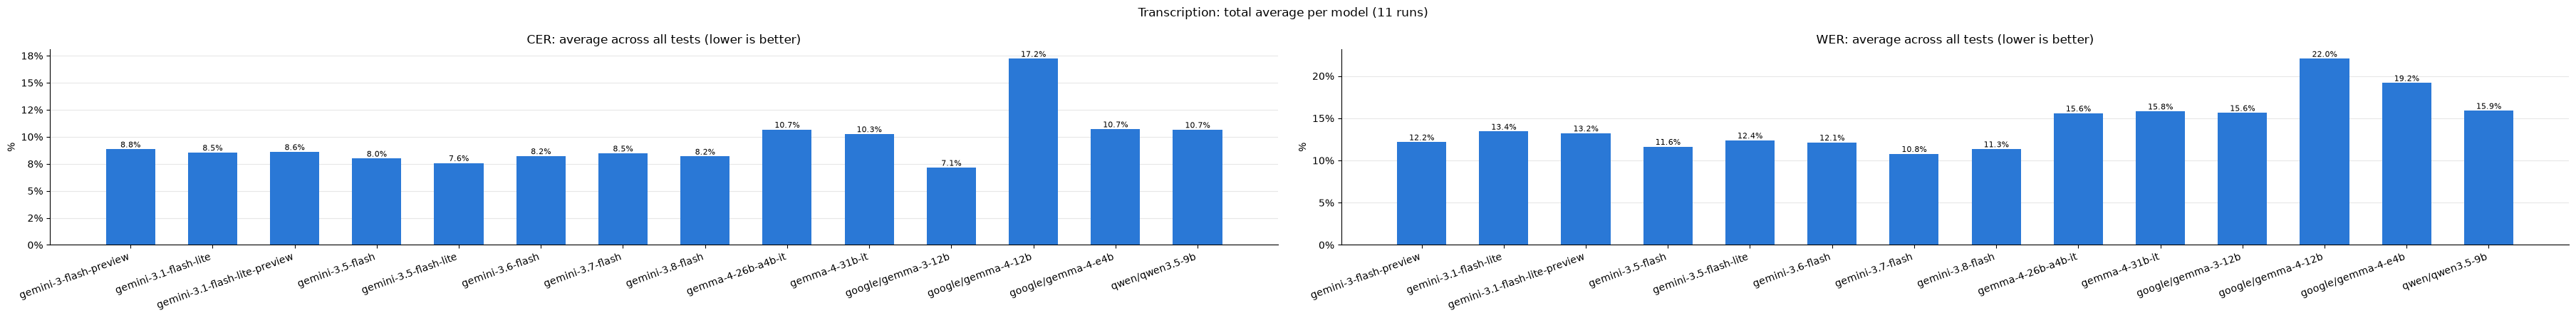

In [76]:
fig, axes = plt.subplots(1, len(metrics), figsize=(width_for(len(average[next(iter(metrics))])) * len(metrics), 4.5), squeeze=False)
for ax, name in zip(axes[0], metrics):
    direction = "lower is better"
    bar(ax, average[name], f"{name}: average across all tests ({direction})")
fig.suptitle(f"{KIND.title()}: total average per model ({n_runs} runs)")
plt.tight_layout()
FIGS["mean_scores"] = fig
plt.show()

## STDs
**Per image:** standard deviation of one model's score on one image across the runs (how much the model varies on that example). Needs 2+ runs.
**Consistency:** average of the per-image STDs, so the typical run-to-run variation across the data. Lower is more consistent.
**Robustness:** STD of the per-image averages, so how much the model's error shifts from one image to another. Lower means more even performance across documents.

In [77]:
display(Markdown(f"### {KIND.title()}: standard deviation"))
if n_runs < 2:
    print("Only 1 run loaded: per-image STD and consistency need 2+ runs of the same test (they show as '-').")
image_std, consistency, robustness = {}, {}, {}
for name, df in metrics.items():
    image_std[name] = df.groupby(["image", "model"])["value"].std().unstack()    # sample STD (n-1) over runs; blank with 1 run
    consistency[name] = image_std[name].mean()
    robustness[name] = image_average[name].std()
    display(Markdown(f"**{name}: STD per image over {n_runs} runs** (first {min(image_preview_window, len(image_std[name]))} of {len(image_std[name])} images)"))
    display(pct_table(image_std[name].head(image_preview_window)))

### Transcription: standard deviation

**CER: STD per image over 11 runs** (first 5 of 5 images)

model,gemini-3-flash-preview,gemini-3.1-flash-lite,gemini-3.1-flash-lite-preview,gemini-3.5-flash,gemini-3.5-flash-lite,gemini-3.6-flash,gemini-3.7-flash,gemini-3.8-flash,gemma-4-26b-a4b-it,gemma-4-31b-it,google/gemma-3-12b,google/gemma-4-12b,google/gemma-4-e4b,qwen/qwen3.5-9b
image,,,,,,,,,,,,,,
img001_0038,0.7%,0.1%,0.1%,0.1%,0.7%,0.1%,0.2%,0.1%,0.7%,0.7%,0.2%,11.4%,0.3%,0.2%
img002_0396,0.3%,0.7%,0.3%,0.2%,0.5%,0.3%,0.3%,0.4%,0.3%,0.3%,0.7%,8.7%,0.3%,1.0%
img003_0096,0.5%,4.4%,1.1%,0.0%,1.4%,0.1%,0.0%,0.5%,0.6%,1.0%,1.0%,5.7%,0.6%,1.0%
img004_0177,1.0%,2.2%,2.2%,0.5%,2.8%,0.1%,1.8%,1.0%,1.9%,0.9%,1.6%,6.7%,1.9%,2.1%
img005_0279,0.9%,0.7%,0.1%,1.0%,1.0%,1.5%,0.1%,0.2%,1.8%,1.0%,0.4%,1.9%,1.0%,1.9%


**WER: STD per image over 11 runs** (first 5 of 5 images)

model,gemini-3-flash-preview,gemini-3.1-flash-lite,gemini-3.1-flash-lite-preview,gemini-3.5-flash,gemini-3.5-flash-lite,gemini-3.6-flash,gemini-3.7-flash,gemini-3.8-flash,gemma-4-26b-a4b-it,gemma-4-31b-it,google/gemma-3-12b,google/gemma-4-12b,google/gemma-4-e4b,qwen/qwen3.5-9b
image,,,,,,,,,,,,,,
img001_0038,0.3%,0.4%,0.3%,0.9%,0.5%,0.4%,1.1%,0.7%,0.4%,0.5%,0.6%,14.7%,1.2%,1.6%
img002_0396,2.4%,2.4%,1.2%,0.9%,1.4%,1.6%,0.8%,1.6%,0.6%,1.0%,1.1%,10.3%,2.0%,0.7%
img003_0096,3.1%,3.1%,2.4%,0.0%,3.5%,0.8%,0.0%,2.3%,2.2%,3.6%,0.8%,4.0%,1.0%,4.4%
img004_0177,1.0%,2.6%,3.3%,1.5%,2.2%,0.6%,2.9%,1.6%,3.7%,1.2%,1.4%,7.3%,2.5%,2.8%
img005_0279,1.3%,1.1%,0.5%,1.4%,0.5%,2.7%,0.7%,0.9%,2.9%,1.6%,0.4%,1.1%,3.4%,2.0%


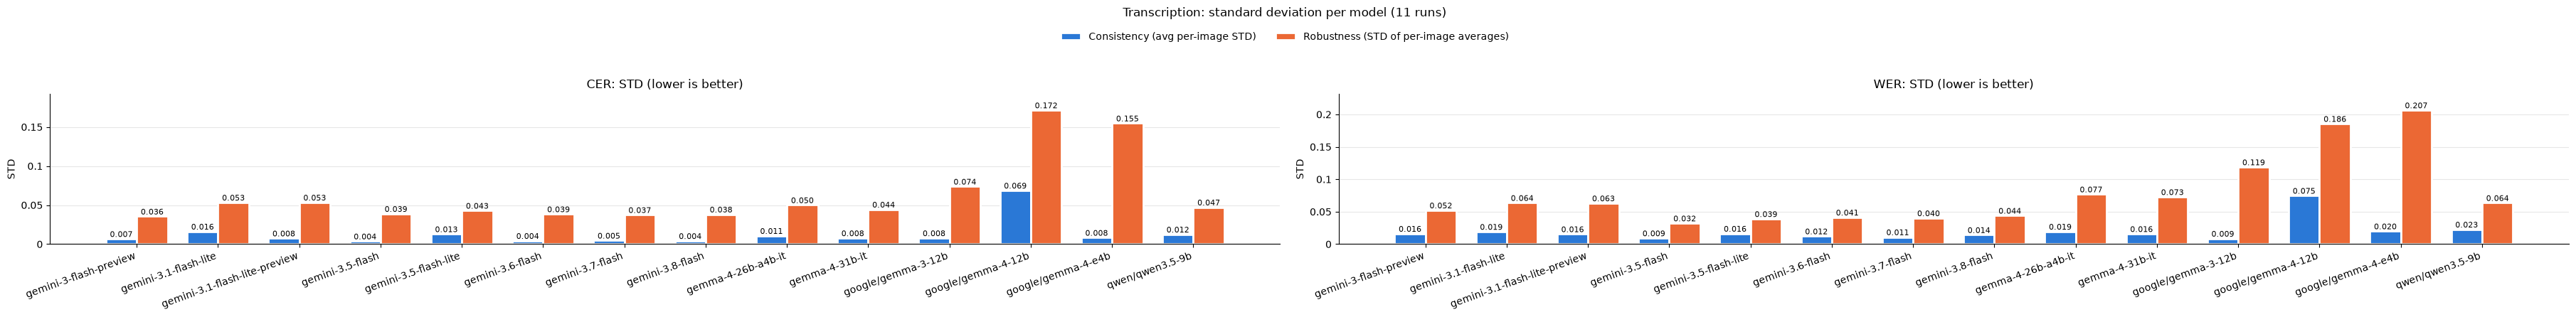

In [78]:
fig, axes = plt.subplots(1, len(metrics), figsize=(width_for(len(consistency[next(iter(metrics))])) * len(metrics), 4.5), squeeze=False)
for ax, name in zip(axes[0], metrics):
    models = consistency[name].index
    xs = range(len(models))
    w = 0.38
    for offset, values, label, color in [(-w / 2, consistency[name], "Consistency (avg per-image STD)", BLUE),
                                         (w / 2, robustness[name].reindex(models), "Robustness (STD of per-image averages)", ORANGE)]:
        bar_x = [x + offset for x in xs]
        ax.bar(bar_x, values, w, color=color, label=label, edgecolor="white", linewidth=2)
        for x, v in zip(bar_x, values):
            if pd.notna(v):
                ax.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(models, rotation=20, ha="right")
    style_axes(ax, f"{name}: STD (lower is better)", "STD")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
    ax.margins(y=0.12)
fig.suptitle(f"{KIND.title()}: standard deviation per model ({n_runs} runs)")
fig.legend(*axes[0][0].get_legend_handles_labels(), frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 0.93))
plt.tight_layout(rect=(0, 0, 1, 0.86))
FIGS["stds"] = fig
plt.show()

## Accuracy
Handwriting: CER accuracy = 100% - CER and WER accuracy = 100% - WER, clipped at 0% (CER/WER pass 100% when a model adds extra text).

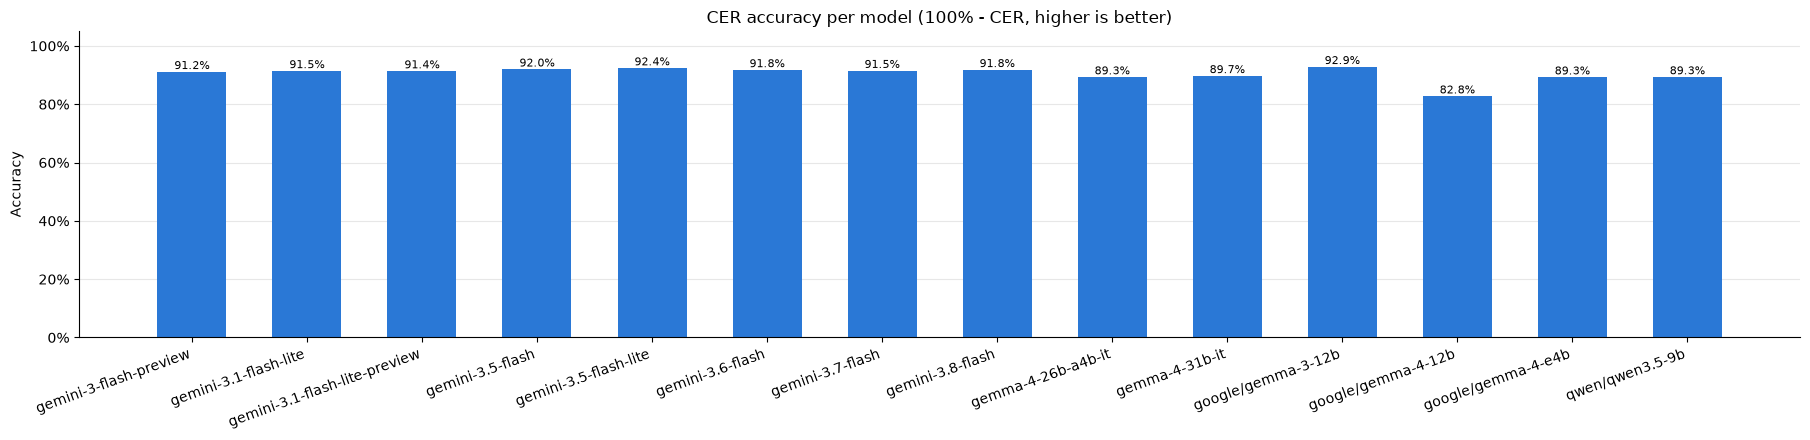

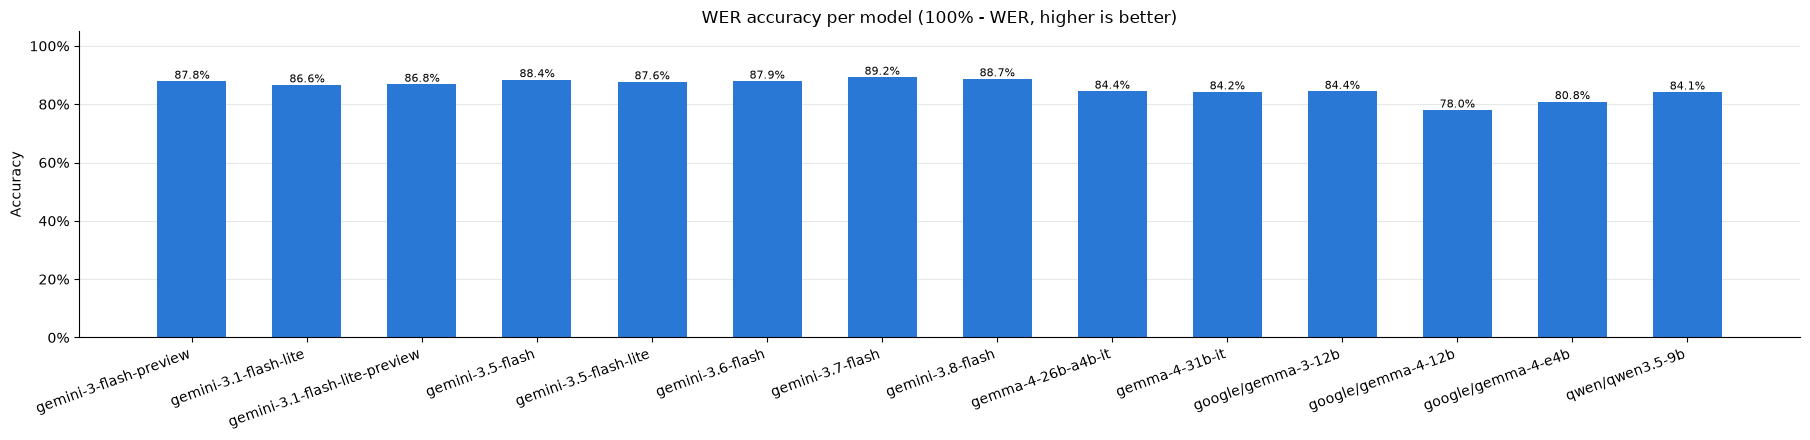

In [79]:
if KIND == "transcription":
    for name in ("CER", "WER"):
        fig, ax = plt.subplots(figsize=(width_for(len(average[name])), 4.5))
        bar(ax, (1 - average[name]).clip(lower=0), f"{name} accuracy per model (100% - {name}, higher is better)",
            "Accuracy", ylim=(0, 105))
        plt.tight_layout()
        FIGS[f"accuracy_{name.lower()}"] = fig
        plt.show()
else:
    print("Forms run: CER/WER accuracy only applies to transcription. See the JSON checks below.")

### First checking if response is valid json

In [80]:
if KIND == "forms":
    fig, ax = plt.subplots(figsize=(width_for(len(average["Invalid JSON"])), 4.5))
    bar(ax, average["Invalid JSON"], "Valid JSON rate per model (higher is better)", "Valid responses", ylim=(0, 105))
    plt.tight_layout()
    FIGS["valid_json"] = fig
    plt.show()
else:
    print("Transcription run: no JSON to check.")

Transcription run: no JSON to check.


## Save Results
Uncomment to save this analysis to `runs/analysis_<date>/`: each chart as PNG, a `report.md` that embeds them,
and `scores_test_<date>.csv` with every average and STD (one row per model per image, plus an `ALL` row per model).

In [81]:
stamp = KIND + "_" + datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
out_dir = Path("runs") / f"analysis_{stamp}"
out_dir.mkdir(parents=True)
rows = []
for name in metrics:
    per_image = pd.DataFrame({"mean": image_average[name].stack(), "std": image_std[name].stack()}).reset_index()
    overall = pd.DataFrame({"mean": average[name], "consistency": consistency[name],
                            "robustness": robustness[name]}).reset_index().assign(image="ALL")
    rows.append(pd.concat([overall, per_image]).assign(metric=name))
results = pd.concat(rows)[["metric", "model", "image", "mean", "std", "consistency", "robustness"]]
results.to_csv(out_dir / f"scores_test_{stamp}.csv", index=False)
for fname, fig in FIGS.items():
    fig.savefig(out_dir / f"{fname}.png", dpi=150, bbox_inches="tight")
report = [f"# {KIND.title()} analysis {stamp}", "", f"Runs ({n_runs}): " + ", ".join(Path(r).name for r in runs), ""]
report += [f"## {fname.replace('_', ' ').title()}\n\n![{fname}]({fname}.png)\n" for fname in FIGS]
(out_dir / "report.md").write_text("\n".join(report), encoding="utf-8")
print(f"Saved to {out_dir}")

Saved to runs/analysis_transcription_2026-10-26_20-10-46
